# Análisis Exploratorio de Datos (EDA): glosas médicas
**Proyecto integrador · Minería de Datos** — Entrada: `data/procesados/dataset_glosas_limpio.csv` (316.602 ítems con resultado confirmado, salida del notebook de limpieza).

Cada gráfica se guarda en `reports/figures/` para usarla en el documento IEEE.

## 1. Configuración y carga

In [1]:
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
import os
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RUTA = RAIZ / "data/procesados/dataset_glosas_limpio.csv"
CARPETA_FIG = RAIZ / "reports/figures"
os.makedirs(CARPETA_FIG, exist_ok=True)

COLOR_OK, COLOR_MAL, COLOR_NEUTRO = "#2a9d8f", "#e76f51", "#264653"
ORDEN = ["Recuperada", "No recuperada"]
PALETA = {"Recuperada": COLOR_OK, "No recuperada": COLOR_MAL}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})

def guardar(nombre):
    plt.tight_layout()
    plt.savefig(f"{CARPETA_FIG}/{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()

def corto_medio(texto, ancho=40, lineas=3):
    """Etiqueta en varias líneas (no recorta el nombre de la entidad que va en el centro del texto)."""
    partes = textwrap.wrap(str(texto), width=ancho)
    if len(partes) > lineas:
        partes = partes[:lineas]; partes[-1] = partes[-1][: ancho - 1] + "…"
    return "\n".join(partes)

def barras_h(ax, valores, etiquetas, **kw):
    """Barras horizontales por posición numérica: etiquetas repetidas no se fusionan."""
    pos = np.arange(len(valores))
    ax.barh(pos, valores, **kw)
    ax.set_yticks(pos); ax.set_yticklabels(etiquetas); ax.invert_yaxis()
    return pos

def corto(texto, n=38):
    texto = str(texto)
    return texto if len(texto) <= n else texto[: n - 1] + "…"

df = pd.read_csv(RUTA, encoding="utf-8-sig", low_memory=False)
for c in ["Fecha Factura", "Fecha de la Objecion"]:
    df[c] = pd.to_datetime(df[c], format="ISO8601", errors="raise")

df["no_recuperada"] = (df["Recuperada"] == "No recuperada").astype(int)
df["objecion_global"] = df["Valor TotServicio PROCEDIMIENTO"].isna()   # objeción a la factura completa
TASA_GLOBAL = df["no_recuperada"].mean()

print(f"Filas: {len(df):,} | Columnas: {df.shape[1]}")
print(f"Tasa global de no recuperación: {TASA_GLOBAL:.2%}")

Filas: 316,602 | Columnas: 40
Tasa global de no recuperación: 2.35%


## 2. Calidad de datos: valores nulos

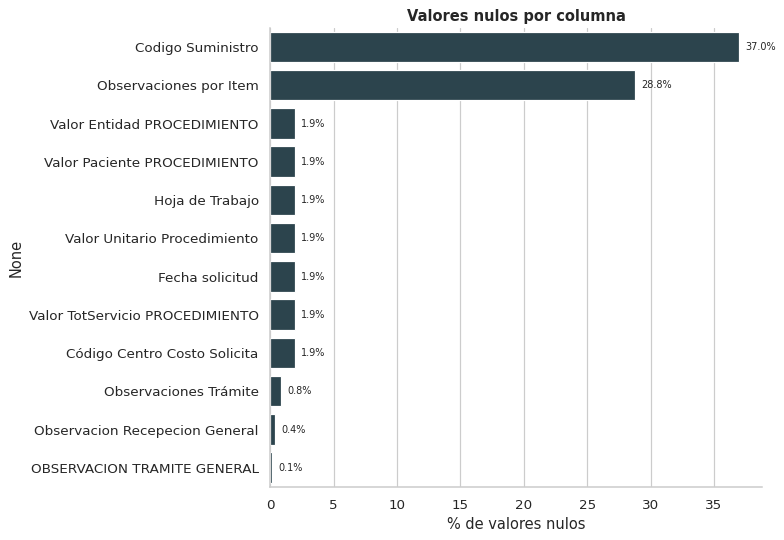

In [2]:
nulos = (df.isna().mean() * 100).sort_values(ascending=False)
nulos = nulos[nulos > 0]

fig, ax = plt.subplots(figsize=(9, 0.4 * len(nulos) + 1.5))
sns.barplot(x=nulos.values, y=nulos.index, color=COLOR_NEUTRO, ax=ax)
for i, v in enumerate(nulos.values):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=8)
ax.set_xlabel("% de valores nulos")
ax.set_title("Valores nulos por columna")
guardar("fig01_nulos")

**Respuesta:** las columnas con más nulos son `Codigo Suministro` (37,0 %) y `Observaciones por Item` (28,8 %): la primera solo aplica a medicamentos e insumos (una consulta o un procedimiento no tiene código de suministro) y la segunda es texto libre opcional del auditor. Siguen siete columnas con 1,9 % (`Valor Unitario`, `Valor TotServicio`, `Valor Entidad`, `Valor Paciente`, `Hoja de Trabajo`, `Fecha solicitud` y `Código Centro Costo Solicita`): coinciden con las 6.151 filas (1,94 %) de **objeciones a la factura completa**, que no apuntan a un servicio concreto, por lo que el nulo tiene significado y no es un error de captura. Los 316.602 ítems confirmados tienen fecha de objeción válida. Las observaciones de trámite presentan entre 0,1 % y 0,8 % de valores ausentes.

**Criterio de imputación:** no se imputó ninguna variable de dinero con promedios o medianas, porque inventaría valores de servicios que no existen. La ausencia se conserva y se marca con `objecion_global`; solo para el K-means (sección 12) se aplica una regla explícita y documentada (valor del servicio = valor objetado, es decir, objeción del 100 %). Las columnas de texto libre y `Codigo Suministro` quedan sin imputar porque no entran como variables numéricas.

## 3. Variable objetivo: desbalance en ítems y en dinero

Valor objetado (confirmados): $42,124 M | aceptado: $7,065 M (16.8% del objetado)


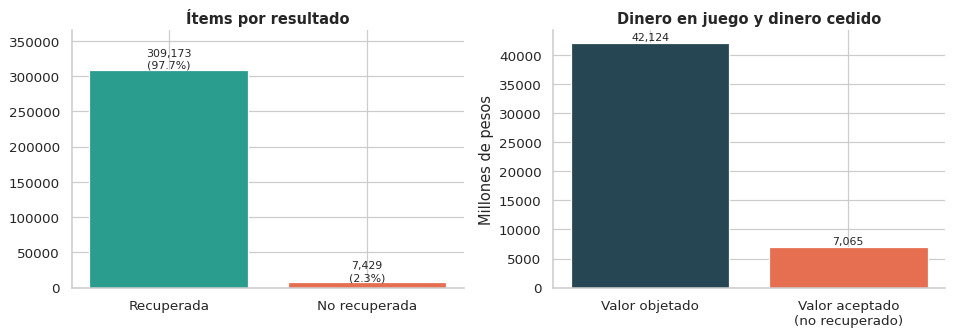

In [3]:
tot_obj = df["Valor Objeción"].sum()
tot_ace = df["Valor Aceptado"].sum()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
cuenta = df["Recuperada"].value_counts().reindex(ORDEN)
axes[0].bar(cuenta.index, cuenta.values, color=[COLOR_OK, COLOR_MAL])
for i, v in enumerate(cuenta.values):
    axes[0].text(i, v, f"{v:,}\n({v/len(df):.1%})", ha="center", va="bottom", fontsize=9)
axes[0].set_title("Ítems por resultado"); axes[0].set_ylim(0, cuenta.max() * 1.18)

axes[1].bar(["Valor objetado", "Valor aceptado\n(no recuperado)"], [tot_obj / 1e6, tot_ace / 1e6],
            color=[COLOR_NEUTRO, COLOR_MAL])
axes[1].set_ylabel("Millones de pesos"); axes[1].set_title("Dinero en juego y dinero cedido")
for i, v in enumerate([tot_obj / 1e6, tot_ace / 1e6]):
    axes[1].text(i, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=9)
guardar("fig02_objetivo")

print(f"Valor objetado (confirmados): ${tot_obj/1e6:,.0f} M | aceptado: ${tot_ace/1e6:,.0f} M "
      f"({tot_ace/tot_obj:.1%} del objetado)")

In [4]:
# Comprobación: ¿qué parte del dinero cedido está en los ítems "No recuperada"?
cedido_nr = df.loc[df["no_recuperada"] == 1, "Valor Aceptado"].sum()
print(f"{df['no_recuperada'].sum():,} ítems no recuperados ({TASA_GLOBAL:.2%}) concentran el {cedido_nr / tot_ace:.1%} del dinero cedido.")

7,429 ítems no recuperados (2.35%) concentran el 100.0% del dinero cedido.


**Respuesta:** hay 7.429 ítems no recuperados (2,35 %) frente a 309.173 recuperados (97,7 %): un desbalance de ~42 a 1. Como el hospital solo cede dinero cuando acepta la glosa, ese 2,35 % de ítems concentra el **100 % del dinero cedido** ($7.065 M, que equivale al 16,8 % de los $42.124 M objetados). Es decir, la clase rara es justo la que cuesta plata.

**Implicación para las métricas:** *accuracy* no sirve, porque un modelo que responda siempre "Recuperada" acierta el 97,7 % sin detectar una sola pérdida. Para evaluar un futuro clasificador se proponen precisión, *recall* y F1 de la clase "No recuperada", PR-AUC (más informativa que ROC-AUC con este desbalance), la matriz de confusión y una métrica en dinero (cuánto del valor aceptado queda en los ítems que el modelo marca como riesgosos). Además, partición estratificada y manejo del desbalance (pesos de clase o ajuste del umbral).

## 4. Distribución de `Valor Objeción` y valores atípicos

Mediana                           7.818000e+03
Media                             1.330506e+05
Percentil 99                      2.269200e+06
Máximo                            1.811384e+08
Límite superior (Q3 + 1,5·IQR)    8.209250e+04
Ítems sobre el límite             4.503900e+04
% de ítems sobre el límite        1.423000e+01


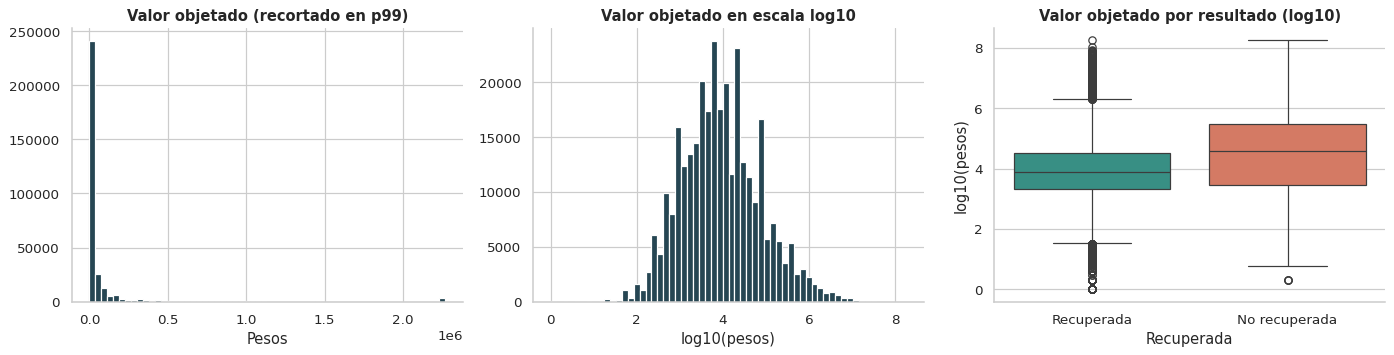

In [5]:
v = df["Valor Objeción"]
v_pos = v[v > 0]
df["log_valor"] = np.log10(v.where(v > 0))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].hist(v.clip(upper=v.quantile(0.99)), bins=60, color=COLOR_NEUTRO)
axes[0].set_title("Valor objetado (recortado en p99)"); axes[0].set_xlabel("Pesos")
axes[1].hist(np.log10(v_pos), bins=60, color=COLOR_NEUTRO)
axes[1].set_title("Valor objetado en escala log10"); axes[1].set_xlabel("log10(pesos)")
sns.boxplot(data=df, x="Recuperada", y="log_valor", order=ORDEN, hue="Recuperada",
            palette=PALETA, legend=False, ax=axes[2])
axes[2].set_title("Valor objetado por resultado (log10)"); axes[2].set_ylabel("log10(pesos)")
guardar("fig03_distribucion_valor")

q1, q3 = v.quantile([0.25, 0.75]); iqr = q3 - q1; limite = q3 + 1.5 * iqr
resumen = pd.Series({
    "Mediana": v.median(), "Media": v.mean(), "Percentil 99": v.quantile(0.99), "Máximo": v.max(),
    "Límite superior (Q3 + 1,5·IQR)": limite,
    "Ítems sobre el límite": int((v > limite).sum()),
    "% de ítems sobre el límite": (v > limite).mean() * 100,
})
print(resumen.round(2).to_string())

**Respuesta:** la mediana es $7.818, pero la media es $133.051 (17 veces mayor), el percentil 99 llega a $2,27 M y el máximo a $181,1 M (≈23.000 veces la mediana). La asimetría es natural: el valor es tarifa × cantidad y el hospital objeta desde insumos de cientos de pesos (sodio cloruro, jeringas, paracetamol, los servicios más frecuentes) hasta cirugías y UCI de millones; un proceso multiplicativo así produce una distribución log-normal. En escala log10 el histograma queda casi simétrico, centrado entre 10^3,8 y 10^4 (≈ $6.000–$10.000).

**Por qué no se eliminaron los atípicos:** la regla Q3 + 1,5·IQR (límite $82.093) marca 45.039 ítems (14,2 %), una proporción demasiado grande para ser error: señala asimetría, no datos malos. Son cirugías, UCI y otros casos reales de alto valor, y además son los que concentran la pérdida (el decil 10 explica ≈98 % del dinero cedido, sección 8). Quitarlos eliminaría el problema de negocio que queremos estudiar.

**Transformación:** logaritmo (log10 en el EDA, log(1+x) en el K-means), que comprime ocho órdenes de magnitud y permite comparar ítems y usar modelos sensibles a la escala. El boxplot muestra además que los ítems no recuperados tienen un valor objetado mayor (mediana ≈10^4,6 ≈ $40.000 frente a ≈10^3,9 ≈ $8.000 de los recuperados).

## 5. Evolución mensual

Ítems sin fecha de objeción (excluidos de esta gráfica): 0


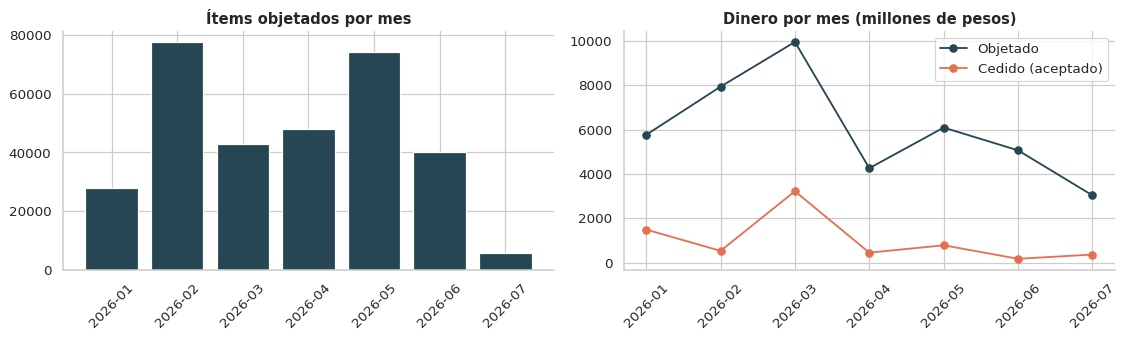

In [6]:
con_fecha = df.dropna(subset=["Fecha de la Objecion"]).copy()
con_fecha["mes"] = con_fecha["Fecha de la Objecion"].dt.to_period("M").astype(str)
mensual = con_fecha.groupby("mes").agg(items=("Factura", "size"),
                                       objetado=("Valor Objeción", "sum"),
                                       perdido=("Valor Aceptado", "sum"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(mensual.index, mensual["items"], color=COLOR_NEUTRO)
axes[0].set_title("Ítems objetados por mes"); axes[0].tick_params(axis="x", rotation=45)
axes[1].plot(mensual.index, mensual["objetado"] / 1e6, marker="o", color=COLOR_NEUTRO, label="Objetado")
axes[1].plot(mensual.index, mensual["perdido"] / 1e6, marker="o", color=COLOR_MAL, label="Cedido (aceptado)")
axes[1].set_title("Dinero por mes (millones de pesos)"); axes[1].legend(); axes[1].tick_params(axis="x", rotation=45)
guardar("fig04_mensual")
print(f"Ítems sin fecha de objeción (excluidos de esta gráfica): {df['Fecha de la Objecion'].isna().sum():,}")
assert mensual["items"].sum() == len(df), "Hay ítems ausentes de la serie mensual."

Febrero tuvo el mayor volumen (77.565 ítems), seguido de mayo (74.219). Marzo concentró el mayor valor: 9.954 millones de COP objetados y 3.226 millones cedidos, equivalentes al 45,7 % de lo cedido en todo el período.

Julio incluye 5.726 ítems confirmados con fechas hasta el día 17. Es un mes parcial. El análisis mensual incluye todos los ítems confirmados.

## 6. Frecuencias de las variables categóricas

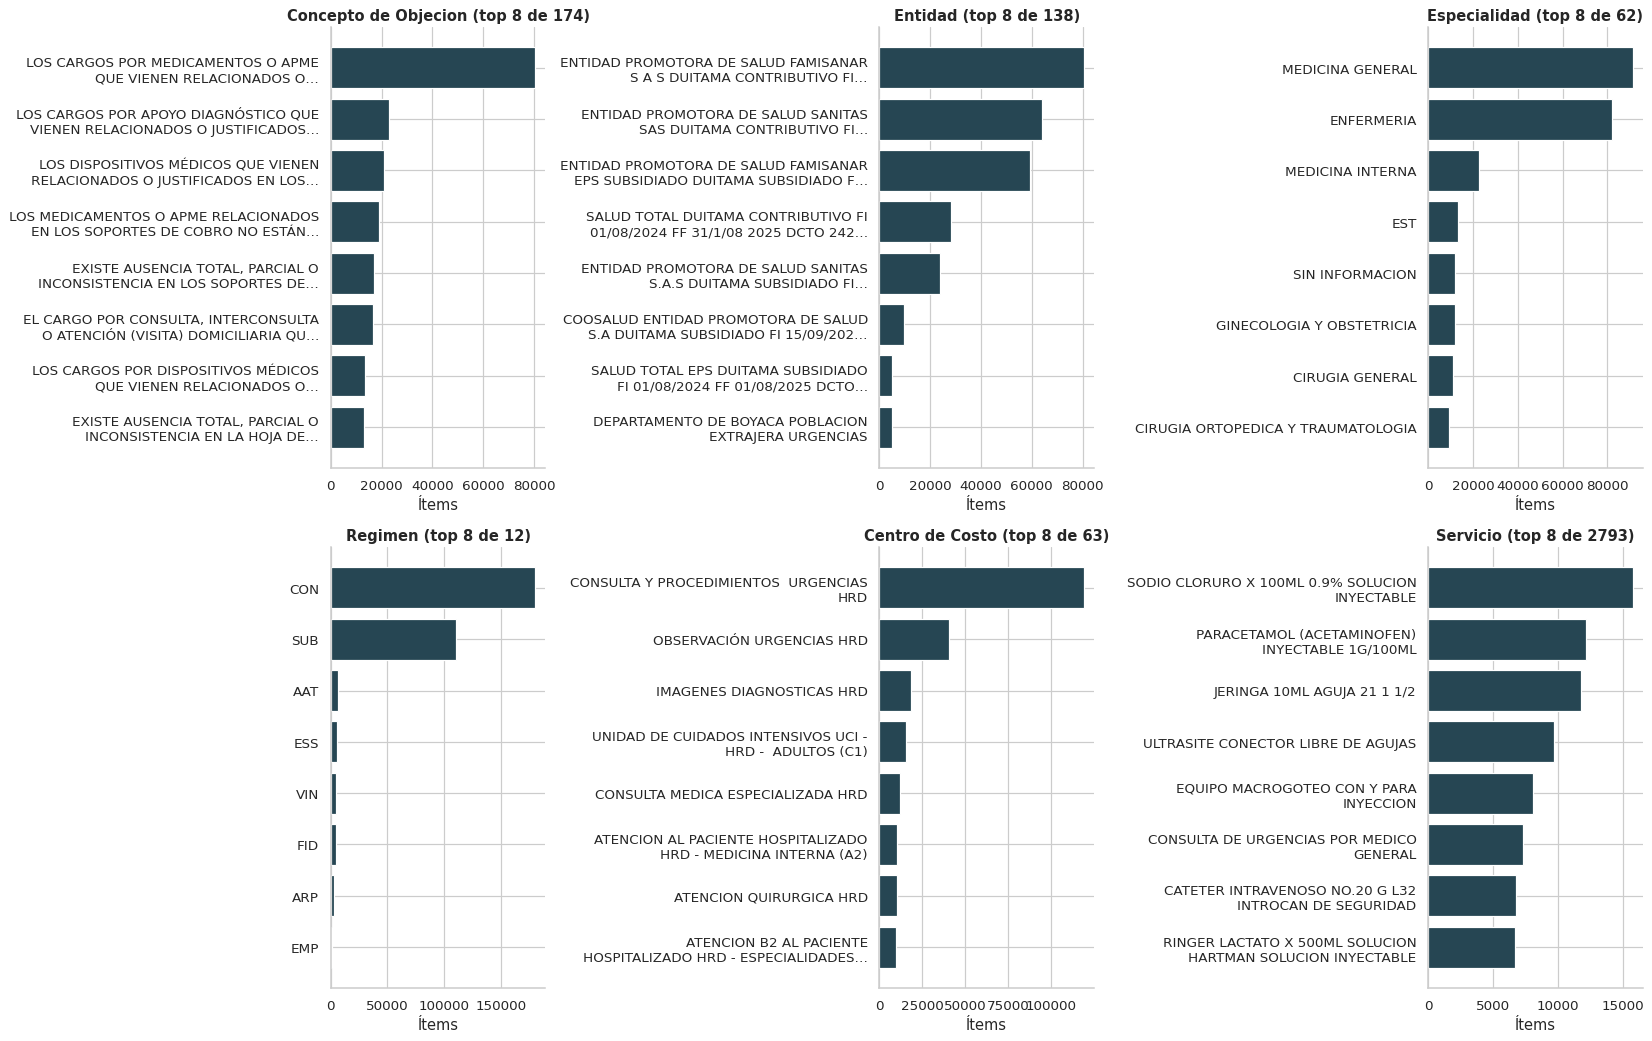

In [7]:
cols_cat = ["Concepto de Objecion", "Entidad", "Especialidad", "Regimen", "Centro de Costo", "Servicio"]
fig, axes = plt.subplots(2, 3, figsize=(19, 12))
for ax, col in zip(axes.ravel(), cols_cat):
    top = df[col].value_counts().head(8)
    barras_h(ax, top.values, [corto_medio(t, 36, 2) for t in top.index], color=COLOR_NEUTRO)
    ax.set_title(f"{col} (top 8 de {df[col].nunique()})"); ax.set_xlabel("Ítems")
guardar("fig05_frecuencias")

**Respuesta:** el motivo dominante es el cobro de medicamentos o APME (≈80 mil ítems, ≈25 %); por familias, diferencias de valor/cantidad suman 54 %, cobertura/pertinencia 21 % y soportes ausentes o inconsistentes 16 %. Dominan **Famisanar (45 % de los ítems)** y **Sanitas (28 %)**; siguen Salud Total (11 %) y Coosalud (4 %). Medicina general y Enfermería juntas superan la mitad de los ítems, el régimen contributivo (CON) pesa ≈57 % y el subsidiado (SUB) ≈35 %, y el grueso viene de urgencias (centros de costo de consulta/procedimientos y observación). Los servicios más frecuentes son insumos baratos (sodio cloruro, paracetamol, jeringas).

**Cardinalidad:** Concepto de objeción 174, Entidad 138, Especialidad 62, Régimen 12, Centro de Costo 63 y Servicio 2.793. Solo `Regimen` admite *one-hot* directo. En las demás, *one-hot* produciría cientos o miles de columnas dispersas: se agrupan en familias o en "OTROS" (como en el K-means), o se usa codificación por frecuencia o *target encoding* calculado únicamente dentro del entrenamiento/validación cruzada (para evitar fuga de información), o modelos que manejan categorías de forma nativa (CatBoost, LightGBM).

## 7. Tasa de no recuperación por categoría

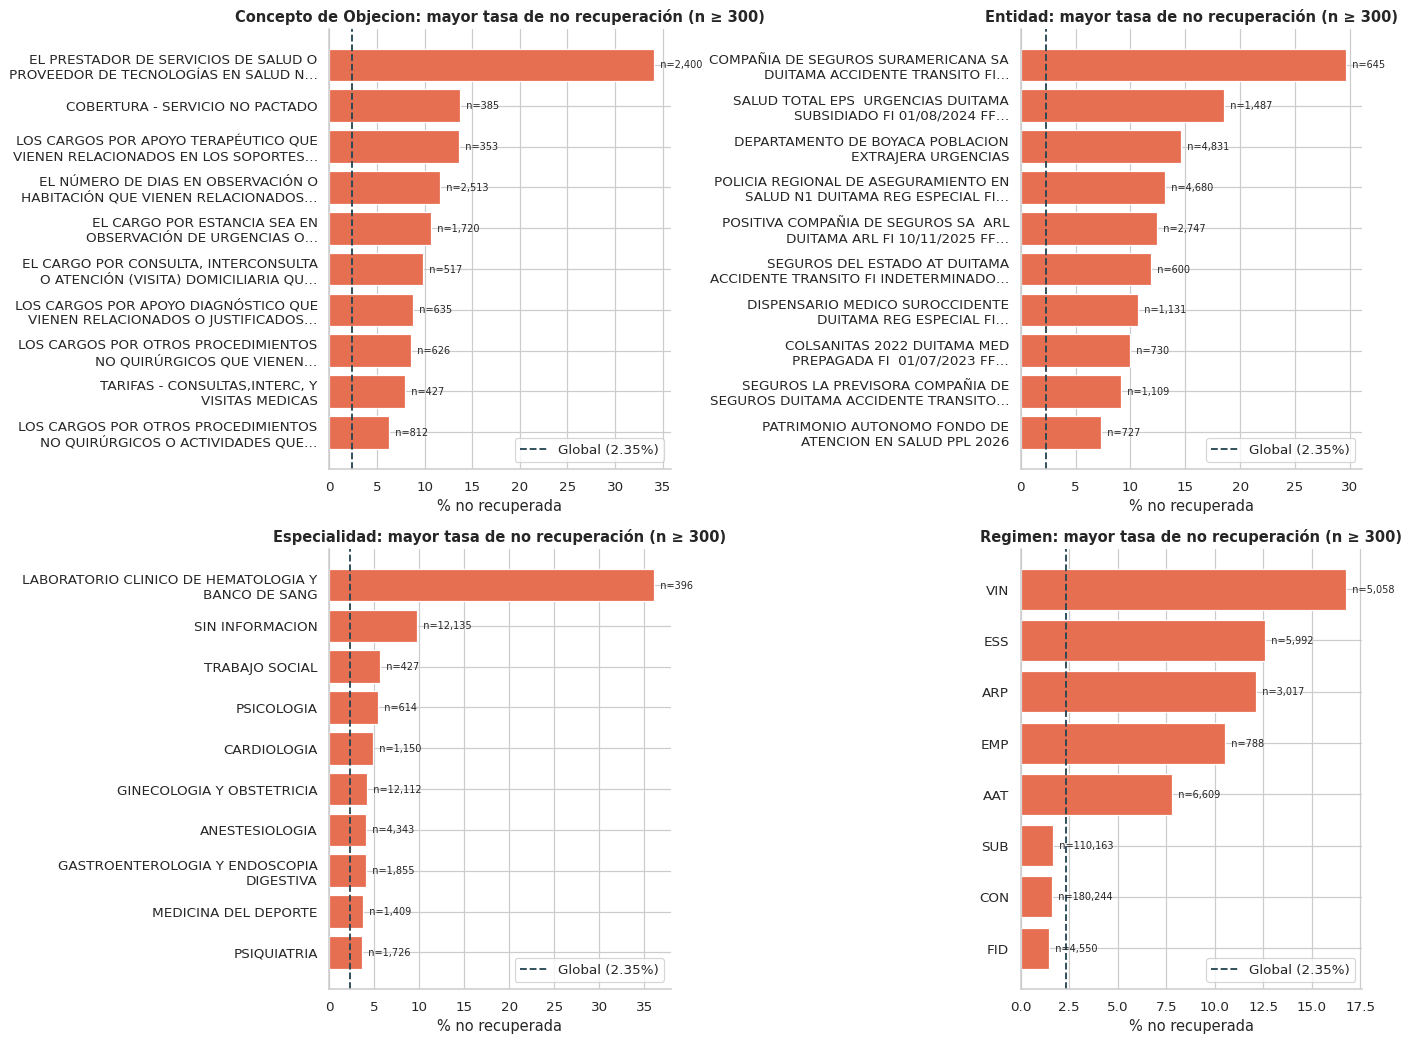

In [8]:
MIN_N = 300
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for ax, col in zip(axes.ravel(), ["Concepto de Objecion", "Entidad", "Especialidad", "Regimen"]):
    g = df.groupby(col).agg(n=("no_recuperada", "size"), tasa=("no_recuperada", "mean"))
    g = g[g["n"] >= MIN_N].sort_values("tasa", ascending=False).head(10)
    barras_h(ax, g["tasa"].values * 100, [corto_medio(t, 36, 2) for t in g.index], color=COLOR_MAL)
    ax.axvline(TASA_GLOBAL * 100, color=COLOR_NEUTRO, ls="--", label=f"Global ({TASA_GLOBAL:.2%})")
    for k, (t, n) in enumerate(zip(g["tasa"], g["n"])):
        ax.text(t * 100, k, f"  n={n:,}", va="center", fontsize=8)
    ax.set_title(f"{col}: mayor tasa de no recuperación (n ≥ {MIN_N})")
    ax.set_xlabel("% no recuperada"); ax.legend(loc="lower right")
guardar("fig06_tasa_por_categoria")

**Respuesta (global = 2,35 %):** hay tasas muy superiores a la global y con muestra razonable.
- **Motivos:** "El prestador de servicios de salud o…" ≈34 % (n = 2.400), la señal más fuerte y mejor respaldada; días/estancia en observación ≈10–12 % (n = 2.513 y 1.720); servicio no pactado ≈14 % (n = 385) y apoyo terapéutico ≈13 % (n = 353), pero con n pequeño.
- **Entidades:** Suramericana ≈30 % (n = 645); Salud Total urgencias ≈18 % (n = 1.487); Dpto. de Boyacá población extranjera ≈14 % (n = 4.831), Policía Regional ≈13 % (n = 4.680) y Positiva ARL ≈12 % (n = 2.747), las de más peso por tamaño.
- **Especialidad:** laboratorio clínico de hematología ≈36 % (n = 396, n pequeño) y "Sin información" ≈10 % (n = 12.135, sólida).
- **Régimen:** VIN ≈17 %, ESS ≈12,5 %, ARP ≈12 %, EMP ≈10,5 % y AAT ≈8 %, todos regímenes pequeños; en cambio CON (≈1,5 %) y SUB (≈1,6 %), que suman casi todo el volumen, están por debajo de la global.

**Cautela:** las tasas con n de unos pocos cientos (hematología, servicio no pactado, apoyo terapéutico, Suramericana) son evidencia débil y se tratan como hipótesis; las de n > 1.500 son más sólidas. Además, tasa alta no significa mucho dinero: por eso se cruza con la sección 9.

## 8. Relación entre el valor objetado y la pérdida (deciles)

El 19% de ítems con mayor Valor Objeción concentra el 99.3% de la pérdida (regla simple para comparar con el clúster 0).
El 20% de ítems con mayor Valor Objeción concentra el 99.4% de la pérdida (regla simple para comparar con el clúster 0).


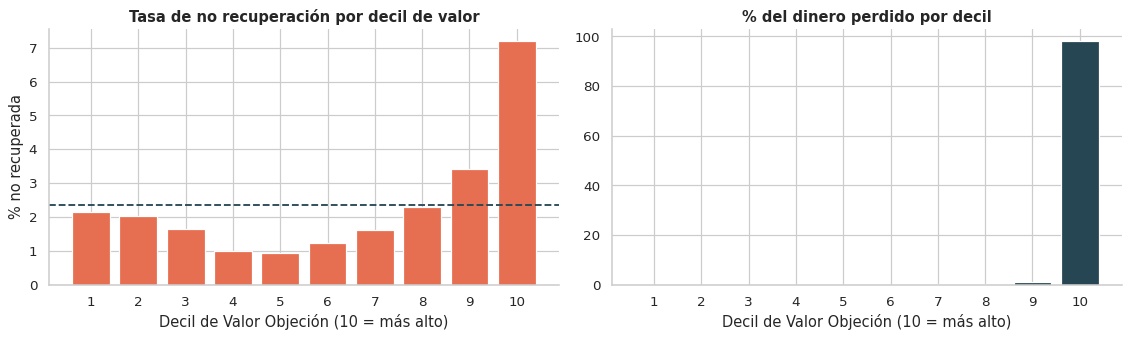

In [9]:
df["decil_valor"] = pd.qcut(df["Valor Objeción"].rank(method="first"), 10, labels=range(1, 11))
dec = df.groupby("decil_valor", observed=True).agg(tasa=("no_recuperada", "mean"), perdido=("Valor Aceptado", "sum"))
dec["pct_perdida"] = dec["perdido"] / dec["perdido"].sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(dec.index.astype(str), dec["tasa"] * 100, color=COLOR_MAL)
axes[0].axhline(TASA_GLOBAL * 100, color=COLOR_NEUTRO, ls="--"); axes[0].set_title("Tasa de no recuperación por decil de valor")
axes[0].set_xlabel("Decil de Valor Objeción (10 = más alto)"); axes[0].set_ylabel("% no recuperada")
axes[1].bar(dec.index.astype(str), dec["pct_perdida"], color=COLOR_NEUTRO)
axes[1].set_title("% del dinero perdido por decil"); axes[1].set_xlabel("Decil de Valor Objeción (10 = más alto)")
guardar("fig07_deciles_valor")

orden = df.sort_values("Valor Objeción", ascending=False)
for frac in (0.19, 0.20):
    k = int(frac * len(df))
    cap = orden["Valor Aceptado"].head(k).sum() / df["Valor Aceptado"].sum()
    print(f"El {frac:.0%} de ítems con mayor Valor Objeción concentra el {cap:.1%} de la pérdida (regla simple para comparar con el clúster 0).")

In [10]:
k10 = int(0.10 * len(df))
cap10 = orden["Valor Aceptado"].head(k10).sum() / df["Valor Aceptado"].sum()
print(f"El 10% de ítems con mayor Valor Objeción (decil 10) concentra el {cap10:.1%} de la pérdida.")
print(dec[["tasa", "pct_perdida"]].assign(tasa=lambda d: d["tasa"] * 100).round(2).to_string())

El 10% de ítems con mayor Valor Objeción (decil 10) concentra el 98.1% de la pérdida.
             tasa  pct_perdida
decil_valor                   
1            2.14         0.00
2            2.03         0.01
3            1.65         0.01
4            0.99         0.02
5            0.93         0.02
6            1.23         0.06
7            1.60         0.14
8            2.28         0.37
9            3.42         1.27
10           7.19        98.10


**Respuesta:** sí. La tasa de no recuperación baja hasta ≈1 % en los deciles 4–5 y sube en los extremos: ≈2,25 % (decil 8), ≈3,4 % (decil 9) y ≈7,2 % (decil 10, tres veces la global). La pérdida se concentra casi por completo en el **decil 10 (≈98 % del dinero cedido)**; el decil 9 aporta ≈1–2 % y los ocho restantes, prácticamente nada.

**Comparación con K-means:** la regla simple del 19 % de ítems con mayor valor concentra el 99,3 % de la pérdida (20 %: 99,4 %), muy cercana al 99,1 % del clúster 0 (19,0 % de las filas). Es decir, **para priorizar solo por dinero, el valor por sí solo ya basta** y hay que decirlo así. Lo que K-means agrega es que (i) el corte surge de tres variables y no de un umbral puesto a mano, (ii) distingue objeciones totales de parciales y (iii) segmenta el 81 % restante en cuatro perfiles con comportamiento distinto, por ejemplo las parciales por diferencias de valor (clústeres 2 y 3) pierden 2,7–2,9 % frente a 0,8–1,3 % en las totales, algo que el decil no muestra.

## 9. Dónde está el dinero perdido: entidad × motivo (Pareto)

Parejas entidad×motivo con pérdida: 607. Bastan 8 para explicar el 80 % del dinero cedido.


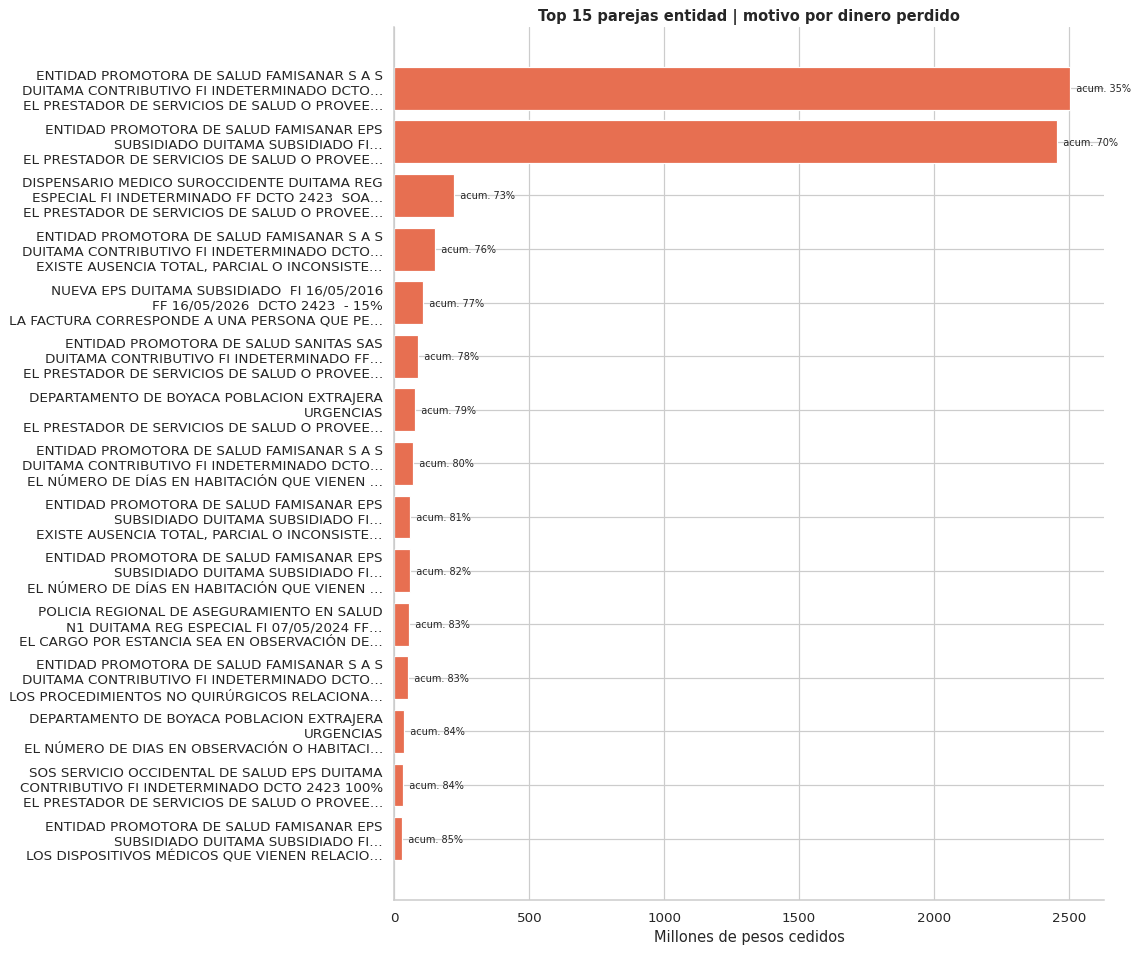

                                                                                                                Entidad                                                                                                                                                                                                                                            Concepto de Objecion  cedido_millones  acumulado_%
0                       ENTIDAD PROMOTORA DE SALUD FAMISANAR S A S DUITAMA CONTRIBUTIVO FI INDETERMINADO DCTO 2423 100%  EL PRESTADOR DE SERVICIOS DE SALUD O PROVEEDOR DE TECNOLOGÍAS EN SALUD NO RADICA LOS SOPORTES DENTRO DE LOS 22 DÍAS HÁBILES SIGUIENTES A LA FECHA DE EXPEDICIÓN DE LA FACTURA CONFORME AL ARTICULO 5 DE LA RESOLUCIÓN 510 DE 2022 O LA QUE MODIFICA O SUSITUYA           2506.0         35.5
1                ENTIDAD PROMOTORA DE SALUD FAMISANAR EPS SUBSIDIADO DUITAMA SUBSIDIADO FI INDETERMINADO DCTO 2423 100%  EL PRESTADOR DE SERVICIOS DE SALUD O PROVEEDOR DE TECNOLOGÍAS EN SA

In [11]:
par = (df.groupby(["Entidad", "Concepto de Objecion"])["Valor Aceptado"].sum()
         .sort_values(ascending=False))
acum = par.cumsum() / par.sum() * 100
top = par.head(15)

fig, ax = plt.subplots(figsize=(13, 11))
etiquetas = [f"{corto_medio(e, 44, 2)}\n{corto(c, 44)}" for e, c in top.index]
barras_h(ax, top.values / 1e6, etiquetas, color=COLOR_MAL)
for k, a in enumerate(acum.head(15).values):
    ax.text(top.values[k] / 1e6, k, f"  acum. {a:.0f}%", va="center", fontsize=8)
ax.set_xlabel("Millones de pesos cedidos"); ax.set_title("Top 15 parejas entidad | motivo por dinero perdido")
guardar("fig08_pareto_perdida")
print(f"Parejas entidad×motivo con pérdida: {int((par > 0).sum()):,}. "
      f"Bastan {int((acum < 80).sum()) + 1} para explicar el 80 % del dinero cedido.")

# Tabla accionable con nombres completos (para cartera y para el informe)
tabla_pareto = top.rename("cedido_COP").reset_index()
tabla_pareto["cedido_millones"] = (tabla_pareto["cedido_COP"] / 1e6).round(0)
tabla_pareto["acumulado_%"] = acum.head(15).values.round(1)
pd.set_option("display.max_colwidth", 90)
display(tabla_pareto[["Entidad", "Concepto de Objecion", "cedido_millones", "acumulado_%"]])

**Respuesta:** de 607 parejas entidad × motivo con pérdida, bastan 8 para explicar el 80 % del dinero cedido. Las dos primeras son **Famisanar** (régimen contributivo y régimen subsidiado) y acumulan ≈70 % del dinero cedido (≈35 % cada una); le siguen, con aportes de pocos puntos, el Dispensario Médico Suroccidente, Nueva EPS, Sanitas, Dpto. de Boyacá (población extranjera), Policía Regional y SOS. Famisanar pesa 45 % de los ítems pero ≥70 % del dinero cedido, así que el valor por ítem objetado es mayor allí.

## 10. Objeciones a la factura completa (sin valor de servicio)

                  items      objetado       perdido   tasa
objecion_global                                           
False            310451  2.550553e+10  1.353577e+09   2.07
True               6151  1.661856e+10  5.711551e+09  16.55


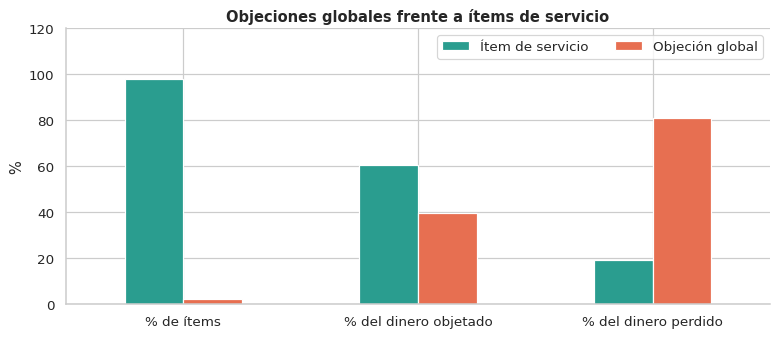

In [12]:
res = df.groupby("objecion_global").agg(items=("Factura", "size"),
                                        objetado=("Valor Objeción", "sum"),
                                        perdido=("Valor Aceptado", "sum"),
                                        tasa=("no_recuperada", "mean"))
pct = res[["items", "objetado", "perdido"]] / res[["items", "objetado", "perdido"]].sum() * 100
pct.index = ["Ítem de servicio", "Objeción global"] if list(res.index) == [False, True] else pct.index

pct.T.rename(index={"items": "% de ítems", "objetado": "% del dinero objetado", "perdido": "% del dinero perdido"}) \
     .plot(kind="bar", color=[COLOR_OK, COLOR_MAL], figsize=(9, 4), rot=0)
plt.title("Objeciones globales frente a ítems de servicio"); plt.ylabel("%"); plt.ylim(0, 120); plt.legend(loc="upper right", ncol=2)
guardar("fig09_objeciones_globales")
print(res.assign(tasa=lambda d: (d["tasa"] * 100).round(2)).to_string())

**Respuesta:** las objeciones a la factura completa son solo 6.151 ítems (1,94 %), pero representan ≈39 % del dinero objetado ($16.619 M) y **≈81 % del dinero cedido ($5.712 M de $7.065 M)**. Su tasa de no recuperación es 16,55 % frente a 2,07 % en los ítems de servicio (8 veces más) y ceden el 34 % de lo objetado frente al 5 % en los ítems. Son un segmento propio y un problema de facturación (la factura completa sale cuestionada), no de un ítem; se atienden con revisión de factura y no ítem a ítem.

## 11. Correlación entre variables numéricas

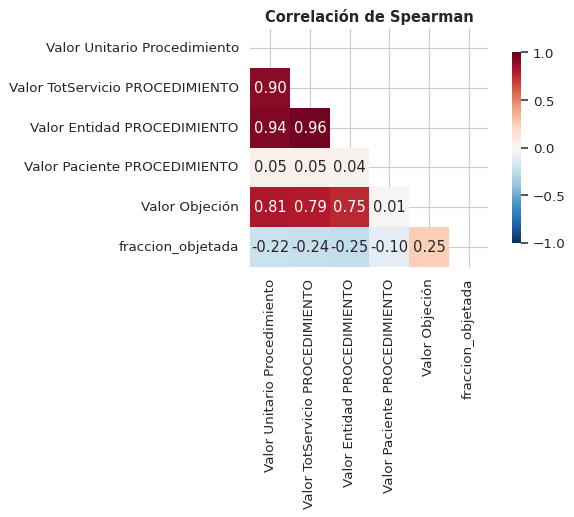

In [13]:
df["fraccion_objetada"] = (df["Valor Objeción"] / df["Valor TotServicio PROCEDIMIENTO"]).clip(0, 1)
num = ["Valor Unitario Procedimiento", "Valor TotServicio PROCEDIMIENTO", "Valor Entidad PROCEDIMIENTO",
       "Valor Paciente PROCEDIMIENTO", "Valor Objeción", "fraccion_objetada"]
corr = df[num].corr(method="spearman")
mascara = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlación de Spearman")
guardar("fig10_correlacion")

**Respuesta:** el bloque de dinero del servicio es casi redundante: `Valor Unitario`, `Valor TotServicio` y `Valor Entidad` tienen correlaciones de Spearman de 0,90 (Unitario–Total), 0,94 (Unitario–Entidad) y 0,96 (Total–Entidad). `Valor Objeción` también se relaciona fuerte con ellas (0,75–0,81), pero menos, porque agrega cuánto del servicio se objeta. `Valor Paciente` casi no se relaciona con nada (0,01–0,05) y `fraccion_objetada` tiene correlación negativa con el tamaño del servicio (−0,22 a −0,25) y positiva con el valor objetado (0,25), o sea, los servicios más caros se objetan más en parte que en su totalidad.

**Por qué K-means usa solo tres variables:** una sola variable de tamaño del servicio (valor del servicio) reemplaza a las tres casi duplicadas (si entraran todas, el tamaño pesaría tres veces en la distancia), se añade el valor objetado y la fracción objetada, que aportan información distinta. `Valor Paciente` no se usa porque no describe la disputa.

## 12. Segmentación con K-means: tipos de glosa y dónde se pierde el dinero

El EDA mostró que el dinero cedido está concentrado en pocos ítems de alto valor. K-means **no predice nada: agrupa objeciones parecidas sin mirar el resultado**. Después se usan los grupos para ver qué tipos de glosa existen y cuáles pierden dinero.

**Regla anti-fuga de información (*data leakage*):** el modelo se entrena solo con lo que se conoce al recibir la objeción (valores y fracción objetada). `Valor Aceptado` y `Recuperada` **no entran al modelo**; se usan únicamente al final para interpretar los grupos.

### 12.1 Variables del modelo y estandarización

Según la matriz de correlación (sección 11), se resume el tamaño del servicio en una sola variable y se usan tres:

| Variable | Qué describe |
|---|---|
| `log_valor_objetado` | Dinero en disputa (log(1+x) para domar los extremos) |
| `log_valor_servicio` | Tamaño del servicio al que pertenece el ítem |
| `pct_objetado` | Fracción del servicio que se objeta (0 a 1): glosa parcial o total |

**Regla para objeciones globales (nulos):** si no hay valor de servicio, se toma el valor objetado como valor del servicio (objeción del 100 %); si el valor objetado supera al del servicio (cantidades mayores a una unidad), el porcentaje se limita a 1. Se estandariza con `StandardScaler` porque K-means usa distancias y `pct_objetado` (0–1) quedaría ignorada frente a los logaritmos (≈1–19).

In [14]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
SEED = 42

valor_obj = df["Valor Objeción"].astype(float)
if valor_obj.isna().any() or valor_obj.lt(0).any():
    raise ValueError("Revisa los importes objetados nulos o negativos antes de segmentar.")
valor_serv = np.maximum(df["Valor TotServicio PROCEDIMIENTO"].fillna(0), valor_obj)
df["log_valor_objetado"] = np.log1p(valor_obj)
df["log_valor_servicio"] = np.log1p(valor_serv)
df["pct_objetado"] = valor_obj.div(valor_serv.where(valor_serv.ne(0))).fillna(0).clip(0, 1)

variables = ["log_valor_objetado", "log_valor_servicio", "pct_objetado"]
print("Nulos en las variables del modelo:", int(df[variables].isnull().sum().sum()))
scaler = StandardScaler()
X = scaler.fit_transform(df[variables])
print("Forma de X:", X.shape)

Nulos en las variables del modelo: 0
Forma de X: (316602, 3)


### 12.2 Elección de K: codo y silueta

           2      3      4     5      6      7      8      9      10
silueta  0.37  0.485  0.474  0.49  0.489  0.478  0.481  0.474  0.483


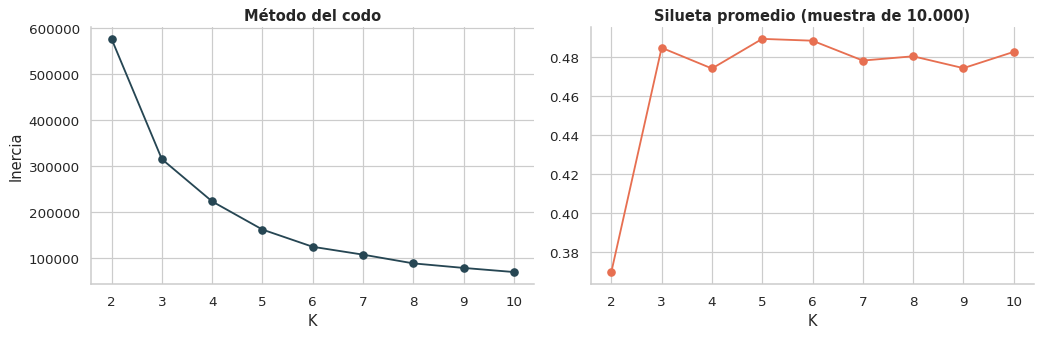

In [15]:
Ks = range(2, 11)
inercia, sil = [], []
for k in Ks:
    km = KMeans(n_clusters=k, init="k-means++", random_state=SEED, n_init=5).fit(X)
    inercia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_, sample_size=10000, random_state=SEED))   # silueta es O(n²): muestra

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(Ks), inercia, marker="o", color=COLOR_NEUTRO); axes[0].set_title("Método del codo")
axes[0].set_xlabel("K"); axes[0].set_ylabel("Inercia")
axes[1].plot(list(Ks), sil, marker="o", color=COLOR_MAL); axes[1].set_title("Silueta promedio (muestra de 10.000)")
axes[1].set_xlabel("K")
guardar("fig11_codo_silueta")
print(pd.Series(sil, index=list(Ks), name="silueta").round(3).to_frame().T.to_string())

**Lectura:** el codo cae con fuerza hasta K = 3–4 y se aplana desde K = 5. La silueta vale ≈0,37 con K = 2 y ≈0,47–0,49 desde K = 3 (máximo 0,490 en K = 5), lo que indica grupos bien separados para datos de dinero. Ojo: entre K = 3 y K = 10 las diferencias son de milésimas, así que la silueta no decide sola. Se elige **K = 5** porque es el menor K que distingue a la vez *alto/medio/bajo valor* y *objeción total/parcial*.

### 12.3 Entrenamiento (K = 5) y centroides

Para que las etiquetas no cambien entre ejecuciones, los clústeres se numeran de mayor a menor valor objetado mediano (el clúster 0 siempre es el de más dinero en juego).

         log_valor_objetado  log_valor_servicio  pct_objetado  valor_objetado_aprox  valor_servicio_aprox
Cluster                                                                                                  
0                     12.26               12.33          0.95              211118.0              225522.0
1                      9.47                9.50          0.98               13014.0               13383.0
2                      9.11               11.53          0.13                9046.0              101260.0
3                      6.72                8.45          0.25                 824.0                4678.0
4                      6.94                6.96          0.98                1031.0                1057.0

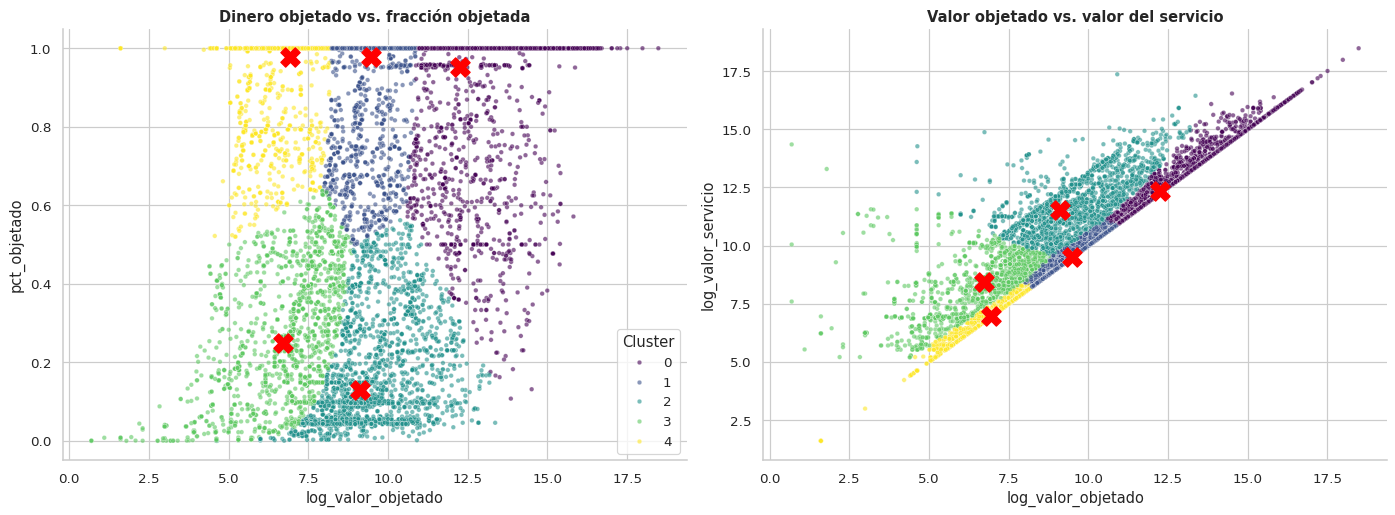

In [16]:
K_FINAL = 5
kmeans = KMeans(n_clusters=K_FINAL, init="k-means++", random_state=SEED, n_init=10)
df["Cluster_raw"] = kmeans.fit_predict(X)

orden_cl = df.groupby("Cluster_raw")["Valor Objeción"].median().sort_values(ascending=False).index
df["Cluster"] = df["Cluster_raw"].map({viejo: nuevo for nuevo, viejo in enumerate(orden_cl)})

centroides = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_[list(orden_cl)]), columns=variables)
centroides["valor_objetado_aprox"] = np.expm1(centroides["log_valor_objetado"]).round(0)
centroides["valor_servicio_aprox"] = np.expm1(centroides["log_valor_servicio"]).round(0)
centroides.index.name = "Cluster"
display(centroides.round(2))

m = df.sample(min(30000, len(df)), random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(data=m, x="log_valor_objetado", y="pct_objetado", hue="Cluster", palette="viridis", s=14, alpha=0.6, ax=axes[0])
axes[0].scatter(centroides["log_valor_objetado"], centroides["pct_objetado"], s=250, c="red", marker="X")
axes[0].set_title("Dinero objetado vs. fracción objetada")
sns.scatterplot(data=m, x="log_valor_objetado", y="log_valor_servicio", hue="Cluster", palette="viridis", s=14, alpha=0.6, ax=axes[1], legend=False)
axes[1].scatter(centroides["log_valor_objetado"], centroides["log_valor_servicio"], s=250, c="red", marker="X")
axes[1].set_title("Valor objetado vs. valor del servicio")
guardar("fig12_clusters")

### 12.4 Perfil de cada clúster y relación con el resultado (solo interpretación)

Aquí **por fin** se usan `Recuperada` y `Valor Aceptado`, que no participaron en la formación de los grupos.

                               Segmento   items  % ítems  % dinero objetado  % dinero perdido  perdido (millones)  pérdida / objetado %  tasa no recuperada %  mediana_obj  pct_medio
Cluster                                                                                                                                                                              
0           Alto valor · objeción total   60188    19.01              92.92             99.06              6998.0                 17.88                  5.31     156900.0       0.95
1          Valor medio · objeción total  109569    34.61               4.37              0.42                30.0                  1.61                  1.28      11850.0       0.98
2        Valor medio · objeción parcial   46074    14.55               2.37              0.50                35.0                  3.54                  2.86       7000.0       0.13
3         Valor bajo · objeción parcial   36285    11.46               0.12              0

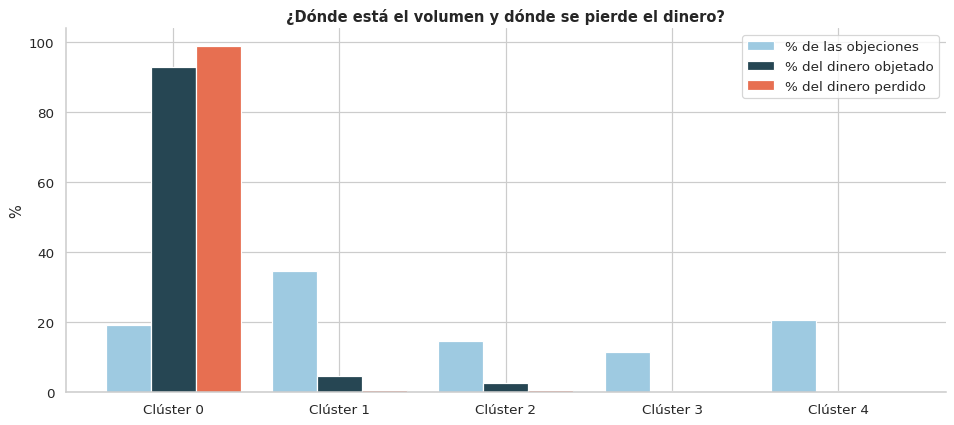

In [17]:
def nombrar(f):
    nivel = "Alto valor" if f["mediana_obj"] >= 100_000 else ("Valor medio" if f["mediana_obj"] >= 5_000 else "Valor bajo")
    tipo = "objeción total" if f["pct_medio"] >= 0.9 else "objeción parcial"
    return f"{nivel} · {tipo}"

perfil = df.groupby("Cluster").agg(items=("Cluster", "size"),
                                   mediana_obj=("Valor Objeción", "median"),
                                   pct_medio=("pct_objetado", "mean"),
                                   objetado=("Valor Objeción", "sum"),
                                   perdido=("Valor Aceptado", "sum"),
                                   tasa_no_rec=("no_recuperada", "mean"))
perfil["Segmento"] = perfil.apply(nombrar, axis=1)
perfil["% ítems"] = perfil["items"] / len(df) * 100
perfil["% dinero objetado"] = perfil["objetado"] / perfil["objetado"].sum() * 100
perfil["% dinero perdido"] = perfil["perdido"] / perfil["perdido"].sum() * 100
perfil["pérdida / objetado %"] = perfil["perdido"] / perfil["objetado"] * 100
perfil["tasa no recuperada %"] = perfil["tasa_no_rec"] * 100
perfil["perdido (millones)"] = (perfil["perdido"] / 1e6).round(0)
tabla_cl = perfil[["Segmento", "items", "% ítems", "% dinero objetado", "% dinero perdido",
                   "perdido (millones)", "pérdida / objetado %", "tasa no recuperada %", "mediana_obj", "pct_medio"]].round(2)
display(tabla_cl)

x = np.arange(K_FINAL); ancho = 0.27
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(x - ancho, perfil["% ítems"], ancho, label="% de las objeciones", color="#9ecae1")
ax.bar(x, perfil["% dinero objetado"], ancho, label="% del dinero objetado", color=COLOR_NEUTRO)
ax.bar(x + ancho, perfil["% dinero perdido"], ancho, label="% del dinero perdido", color=COLOR_MAL)
ax.set_xticks(x); ax.set_xticklabels([f"Clúster {c}" for c in perfil.index]); ax.set_ylabel("%"); ax.legend()
ax.set_title("¿Dónde está el volumen y dónde se pierde el dinero?")
guardar("fig13_kmeans_perdida")

### 12.5 Cruce con las objeciones globales (sección 10)

A las objeciones globales se les asigna fracción 1 y valor de servicio = valor objetado, así que K-means las mezcla con las objeciones totales a ítems del mismo valor. La tabla muestra cuánto de cada clúster son objeciones globales, para no confundir dos problemas distintos (factura completa vs. ítem).

In [18]:
cruce = (df.groupby("Cluster")
           .agg(items=("Cluster", "size"),
                globales=("objecion_global", "sum"),
                perdido_globales=("Valor Aceptado", lambda s: s[df.loc[s.index, "objecion_global"]].sum()),
                perdido_total=("Valor Aceptado", "sum")))
cruce["% del clúster que es global"] = (cruce["globales"] / cruce["items"] * 100).round(1)
cruce["% de la pérdida del clúster por globales"] = (cruce["perdido_globales"] / cruce["perdido_total"] * 100).round(1)
cruce["% de todas las globales en este clúster"] = (cruce["globales"] / cruce["globales"].sum() * 100).round(1)
display(cruce[["items", "globales", "% del clúster que es global",
               "% de la pérdida del clúster por globales", "% de todas las globales en este clúster"]])

          items  globales  % del clúster que es global  % de la pérdida del clúster por globales  % de todas las globales en este clúster
Cluster                                                                                                                                  
0         60188      5609                          9.3                                      81.6                                     91.2
1        109569       526                          0.5                                       5.1                                      8.6
2         46074         0                          0.0                                       0.0                                      0.0
3         36285         0                          0.0                                       0.0                                      0.0
4         64486        16                          0.0                                       0.8                                      0.3

### 12.6 Estabilidad: ¿los clústeres dependen del azar?

Se compara con el *Adjusted Rand Index* (ARI: 1 = agrupaciones idénticas, 0 = azar) (a) con distintas semillas y (b) entrenando solo con la mitad de los datos y asignando el resto.

In [19]:
base = df["Cluster_raw"].values
ari_semillas = [adjusted_rand_score(base, KMeans(K_FINAL, n_init=1, random_state=s).fit_predict(X)) for s in [1, 7, 21, 99]]
mitad = np.random.RandomState(SEED).rand(len(X)) < 0.5
ari_mitad = adjusted_rand_score(base, KMeans(K_FINAL, n_init=10, random_state=SEED).fit(X[mitad]).predict(X))
print("ARI con 4 semillas distintas:", np.round(ari_semillas, 3))
print(f"ARI entrenando con el 50 % de los datos y prediciendo todo: {ari_mitad:.3f}")

ARI con 4 semillas distintas: [1. 1. 1. 1.]
ARI entrenando con el 50 % de los datos y prediciendo todo: 0.999


**Lectura (resultados del ajuste reproducible):** ARI = 1,0 con las cuatro semillas y 0,999 con el 50 % de los datos, o sea, los segmentos son estables y no dependen del azar.

### 12.7 Conclusiones de la segmentación

| Clúster | Segmento | % objeciones | % dinero objetado | % dinero perdido | Tasa no recuperada |
|---|---|---|---|---|---|
| 0 | **Alto valor · objeción total** | 19,0 % | 92,9 % | **99,1 %** | 5,3 % |
| 1 | Valor medio · objeción total | 34,6 % | 4,4 % | 0,4 % | 1,3 % |
| 2 | Valor medio · objeción parcial | 14,6 % | 2,4 % | 0,5 % | 2,9 % |
| 3 | Valor bajo · objeción parcial | 11,5 % | 0,1 % | 0,0 % | 2,7 % |
| 4 | Valor bajo · objeción total | 20,4 % | 0,2 % | 0,0 % | 0,8 % |

1. **El dinero se pierde en un solo segmento (clúster 0):** una de cada cinco objeciones concentra el 92,9 % del dinero objetado y $6.998 M de los $7.065 M cedidos (99,1 %). Allí se pierde el 17,9 % de lo objetado y la tasa de no recuperación (5,3 %) es más del doble de la global. Es la bandeja que cartera debe atender primero y con revisión experta.
2. **El 81 % restante (clústeres 1 a 4) aporta menos del 1 % de la pérdida** (≈$67 M): respuestas estandarizadas o semiautomáticas; aquí se ahorra tiempo del equipo.
3. **Las objeciones parciales por diferencias de valor (clústeres 2 y 3)** pierden proporcionalmente más (2,7–2,9 % frente a 0,8–1,3 % en las totales), están dominadas por motivos de diferencias de valor/cantidad (95–99 %) y se concentran en Salud Total (clúster 2) y Famisanar (clúster 3): conviene revisar la carga de tarifas pactadas con esas EPS.
4. **Las objeciones pequeñas y totales (clúster 4)** son las más defendibles (0,8 %) y sobrerrepresentan soportes ausentes o inconsistentes: se resuelven adjuntando documentación y son candidatas a automatizar.

**Limitaciones:**
- La segmentación la determina el dinero; entidad, motivo y especialidad describen los grupos pero no los forman (con *one-hot* ponderado las categóricas no cambiaban los grupos y empeoraban la silueta de 0,49 a 0,33).
- El clúster 0 explica el 99 % de la pérdida por la cola pesada del valor, y la regla simple del decil 10 o del 19 % superior da casi lo mismo (sección 8): lo que K-means agrega es la lectura de los otros cuatro perfiles.
- K-means describe, no predice: no reemplaza al clasificador del proyecto, lo complementa como regla de priorización. Si el clúster se usa como variable de entrada del clasificador, K-means debe ajustarse **solo con el conjunto de entrenamiento** para evitar fuga de información.
- Las familias de motivo, entidad y área son reglas de texto definidas por el equipo y se pueden refinar.

### 12.7 Perfiles categóricos por clúster
La tabla muestra qué categorías tienen mayor presencia relativa en cada grupo frente al conjunto confirmado.

In [20]:
def familia_motivo(t):
    t = str(t).upper()
    if 'COPAGO' in t or 'CUOTAS MODERADORAS' in t: return 'COPAGOS / CUOTAS MODERADORAS'
    if 'NO RADICA' in t or 'RADICACI' in t: return 'PLAZO DE RADICACION'
    if 'DIFERENCIA' in t or 'NO PACTADOS' in t or 'TARIFA' in t: return 'DIFERENCIAS DE VALOR / CANTIDAD'
    if 'AUSENCIA' in t or 'INCONSISTENCIA' in t: return 'SOPORTES AUSENTES / INCONSISTENTES'
    if 'COBERTURA' in t or 'PERTINENTE' in t: return 'COBERTURA / PERTINENCIA'
    if 'AUTORIZACI' in t or 'RIPS' in t: return 'AUTORIZACION / RIPS'
    if 'OTRO RESPONSABLE' in t or 'OTRA RESPONSABLE' in t or 'RED INTEGRAL' in t or ('ATENCI' in t and 'URGENCIA' in t): return 'DERECHOS / RED / RESPONSABLE DE PAGO'
    return 'OTROS MOTIVOS'

def familia_entidad(t):
    t = str(t).upper()
    for clave, fam in [('FAMISANAR', 'FAMISANAR'), ('SANITAS', 'SANITAS'), ('SALUD TOTAL', 'SALUD TOTAL'), ('COOSALUD', 'COOSALUD'),
                       ('PROTEGER', 'PROTEGER'), ('SOAT', 'SOAT / ACCIDENTE TRANSITO'), ('ACCIDENTE', 'SOAT / ACCIDENTE TRANSITO'),
                       ('FIDUCI', 'FOMAG / FIDUCIARIA'), ('DEPARTAMENTO', 'ENTES TERRITORIALES'), ('SECRETARIA', 'ENTES TERRITORIALES')]:
        if clave in t: return fam
    return 'OTRAS ENTIDADES'

def familia_area(t):
    t = str(t).upper()
    for clave, fam in [('UCI', 'UCI / CUIDADO INTENSIVO'), ('INTENSIV', 'UCI / CUIDADO INTENSIVO'), ('URGENCIAS', 'URGENCIAS'),
                       ('QUIRURG', 'QUIRURGICO'), ('IMAGEN', 'APOYO DIAGNOSTICO'), ('LABORATORIO', 'APOYO DIAGNOSTICO'),
                       ('HOSPITALIZ', 'HOSPITALIZACION'), ('CONSULTA', 'CONSULTA EXTERNA')]:
        if clave in t: return fam
    return 'OTROS SERVICIOS'

def mapear(serie, f):                       # aplica la regla solo a los valores únicos (rápido)
    return serie.map({u: f(u) for u in serie.dropna().unique()})

df['Motivo'] = mapear(df['Concepto de Objecion'], familia_motivo)
df['Tipo Entidad'] = mapear(df['Entidad'], familia_entidad)
df['Area'] = mapear(df['Centro de Costo'], familia_area)
top_esp = df['Especialidad'].value_counts().head(8).index
df['Especialidad_g'] = df['Especialidad'].where(df['Especialidad'].isin(top_esp), 'OTRAS ESPECIALIDADES')
top_reg = df['Regimen'].value_counts().head(5).index
df['Regimen_g'] = df['Regimen'].where(df['Regimen'].isin(top_reg), 'OTROS REGIMENES')

def categoria_distintiva(data, var, min_share=0.05):
    por_cluster = pd.crosstab(data['Cluster'], data[var], normalize='index')
    global_ = data[var].value_counts(normalize=True)
    filas = {}
    for c in por_cluster.index:
        s = por_cluster.loc[c]
        lift = (s / global_[s.index]).where(s >= min_share)
        cat = lift.idxmax()
        filas[c] = f"{cat} ({s[cat]*100:.0f}% vs {global_[cat]*100:.0f}%)"
    return pd.Series(filas)

perfil_cat = pd.DataFrame({
    'Motivo': categoria_distintiva(df, 'Motivo'),
    'Entidad': categoria_distintiva(df, 'Tipo Entidad'),
    'Área': categoria_distintiva(df, 'Area'),
    'Especialidad': categoria_distintiva(df, 'Especialidad_g'),
    'Régimen': categoria_distintiva(df, 'Regimen_g'),
})
perfil_cat.index.name = 'Cluster'
display(perfil_cat)

                                                  Motivo                     Entidad                                Área                          Especialidad           Régimen
Cluster                                                                                                                                                                         
0                         AUTORIZACION / RIPS (7% vs 2%)  OTRAS ENTIDADES (9% vs 4%)         OTROS SERVICIOS (20% vs 9%)           SIN INFORMACION (10% vs 4%)  CON (53% vs 57%)
1                   COBERTURA / PERTINENCIA (28% vs 21%)        SANITAS (31% vs 28%)  UCI / CUIDADO INTENSIVO (8% vs 6%)               ENFERMERIA (32% vs 26%)  SUB (37% vs 35%)
2           DIFERENCIAS DE VALOR / CANTIDAD (95% vs 54%)    SALUD TOTAL (31% vs 11%)        CONSULTA EXTERNA (20% vs 4%)  GINECOLOGIA Y OBSTETRICIA (9% vs 4%)  CON (70% vs 57%)
3           DIFERENCIAS DE VALOR / CANTIDAD (99% vs 54%)      FAMISANAR (76% vs 45%)              URGENCIAS (74% vs

### 12.8 Sensibilidad a la inclusión de variables categóricas
Se compara el mismo K con tres ponderaciones de las categorías codificadas como indicadores binarios, en una muestra reproducible de hasta 40.000 ítems.

In [21]:
cat_cols = ['Motivo', 'Tipo Entidad', 'Area', 'Especialidad_g', 'Regimen_g']
muestra = df.sample(min(40000, len(df)), random_state=SEED)
Xn = StandardScaler().fit_transform(muestra[variables])
dummies = pd.get_dummies(muestra[cat_cols].astype(str)).astype(float).values

lab_num = KMeans(K_FINAL, n_init=5, random_state=SEED).fit_predict(Xn)
filas = [{'Variante': 'Solo numéricas (modelo elegido)', 'Columnas': Xn.shape[1],
          'Silueta': silhouette_score(Xn, lab_num, sample_size=10000, random_state=SEED), 'Parecido con solo-numérico (ARI)': 1.0}]
for w in [0.35, 0.7, 1.0]:
    Xm = np.hstack([Xn, dummies * w])
    lab = KMeans(K_FINAL, n_init=5, random_state=SEED).fit_predict(Xm)
    filas.append({'Variante': f'Numéricas + categóricas (one-hot, w={w})', 'Columnas': Xm.shape[1],
                  'Silueta': silhouette_score(Xm, lab, sample_size=10000, random_state=SEED),
                  'Parecido con solo-numérico (ARI)': adjusted_rand_score(lab_num, lab)})
comparacion = pd.DataFrame(filas).round(3)
display(comparacion)

                                    Variante  Columnas  Silueta  Parecido con solo-numérico (ARI)
0            Solo numéricas (modelo elegido)         3    0.493                             1.000
1  Numéricas + categóricas (one-hot, w=0.35)        42    0.333                             0.992
2   Numéricas + categóricas (one-hot, w=0.7)        42    0.206                             0.956
3   Numéricas + categóricas (one-hot, w=1.0)        42    0.151                             0.729

**Lectura:**

- Con un peso bajo (`w=0,35`) las categóricas **no cambian los grupos** (ARI ≈ 0,99: son prácticamente los mismos) y solo empeoran la silueta (0,49 → 0,33).
- Si se les sube el peso, los grupos empiezan a depender de la entidad o el motivo (ARI baja a 0,73), pero **se vuelven borrosos** (silueta 0,15): K-Means con muchas columnas 0/1 deja de ser una buena herramienta (para datos mixtos lo propio sería K-Prototypes).

**Decisión:** el modelo final usa **solo las 3 variables numéricas**. Convertir las categóricas a números **no era necesario ni mejoraba** la segmentación; su mejor uso es el que ya hicimos en 8.2: **describir** cada grupo. El resultado se puede explicar en una frase y, además, no depende de ninguna elección arbitraria de pesos.

## 13. Resumen de cifras clave para el informe

In [22]:
print(f"Ítems confirmados: {len(df):,}")
print(f"Tasa de no recuperación: {TASA_GLOBAL:.2%}")
print(f"Dinero objetado: ${df['Valor Objeción'].sum()/1e6:,.0f} M | cedido: ${df['Valor Aceptado'].sum()/1e6:,.0f} M "
      f"({df['Valor Aceptado'].sum()/df['Valor Objeción'].sum():.1%})")
print(f"Objeciones globales: {df['objecion_global'].mean():.2%} de los ítems")
print(f"Clúster 0 (alto valor · objeción total): {(df['Cluster']==0).mean():.1%} de los ítems, "
      f"{df.loc[df['Cluster']==0, 'Valor Aceptado'].sum()/df['Valor Aceptado'].sum():.1%} del dinero cedido")
print(f"Figuras guardadas en: {CARPETA_FIG.relative_to(RAIZ)}")
print(sorted(os.listdir(CARPETA_FIG)))

Ítems confirmados: 316,602
Tasa de no recuperación: 2.35%
Dinero objetado: $42,124 M | cedido: $7,065 M (16.8%)
Objeciones globales: 1.94% de los ítems
Clúster 0 (alto valor · objeción total): 19.0% de los ítems, 99.1% del dinero cedido
Figuras guardadas en: reports/figures
['fig01_nulos.png', 'fig02_objetivo.png', 'fig03_distribucion_valor.png', 'fig04_mensual.png', 'fig05_frecuencias.png', 'fig06_tasa_por_categoria.png', 'fig07_deciles_valor.png', 'fig08_pareto_perdida.png', 'fig09_objeciones_globales.png', 'fig10_correlacion.png', 'fig11_codo_silueta.png', 'fig12_clusters.png', 'fig13_kmeans_perdida.png', 'fig14_concepto_oficial.png']


## 14. Tablas de verificación del análisis

Estas tablas permiten contrastar las cifras redondeadas con el cálculo a partir del CSV privado.

In [23]:
ent = df["Entidad"].str.upper()
total_ced = df["Valor Aceptado"].sum()

print("== Sec. 5: mes a mes ==")
print(mensual.assign(objetado_M=(mensual["objetado"] / 1e6).round(0), cedido_M=(mensual["perdido"] / 1e6).round(0),
                     pct_cedido_total=(mensual["perdido"] / total_ced * 100).round(1))[["items", "objetado_M", "cedido_M", "pct_cedido_total"]].to_string())

print("\n== Sec. 6: participación ==")
print((df["Concepto de Objecion"].value_counts(normalize=True).head(3) * 100).round(1).to_string())
for k in ["FAMISANAR", "SANITAS", "SALUD TOTAL", "COOSALUD"]:
    m_ = ent.str.contains(k, na=False)
    print(f"{k}: {m_.mean():.1%} de los ítems | {df.loc[m_, 'Valor Aceptado'].sum() / total_ced:.1%} del dinero cedido")
print(f"Medicina general + Enfermería: {df['Especialidad'].isin(['MEDICINA GENERAL', 'ENFERMERIA']).mean():.1%} de los ítems")
print((df["Regimen"].value_counts(normalize=True).head(3) * 100).round(1).to_string())
print({c: df[c].nunique() for c in ["Concepto de Objecion", "Entidad", "Especialidad", "Regimen", "Centro de Costo", "Servicio"]})

print("\n== Sec. 7: tasas más altas con n ==")
for col in ["Concepto de Objecion", "Entidad", "Especialidad", "Regimen"]:
    g = df.groupby(col).agg(n=("no_recuperada", "size"), tasa=("no_recuperada", "mean"))
    g = g[g["n"] >= MIN_N].sort_values("tasa", ascending=False).head(6)
    print(f"-- {col}"); print(g.assign(tasa=(g["tasa"] * 100).round(1)).to_string())

print("\n== Sec. 10: globales vs ítems ==")
print(pct.round(1).to_string())
print((res["perdido"] / res["objetado"] * 100).round(1).rename("pérdida / objetado %").to_string())

print("\n== Sec. 11: correlación Spearman ==")
print(corr.round(2).to_string())

print("\n== Sec. 4: boxplot, medianas ==")
print(df.groupby("Recuperada")["Valor Objeción"].median().round(0).to_string())

== Sec. 5: mes a mes ==
         items  objetado_M  cedido_M  pct_cedido_total
mes                                                   
2026-01  27730      5767.0    1499.0              21.2
2026-02  77565      7937.0     539.0               7.6
2026-03  43019      9954.0    3226.0              45.7
2026-04  48136      4263.0     458.0               6.5
2026-05  74219      6094.0     790.0              11.2
2026-06  40207      5069.0     182.0               2.6
2026-07   5726      3040.0     372.0               5.3

== Sec. 6: participación ==
Concepto de Objecion
LOS CARGOS POR MEDICAMENTOS O APME QUE VIENEN RELACIONADOS O JUSTIFICADOS EN LOS SOPORTES DE COBRO, PRESENTAN DIFERENCIAS CON LOS VALORES PACTADOS O ESTABLECIDOS POR LA NORMA    25.4
LOS CARGOS POR APOYO DIAGNÓSTICO QUE VIENEN RELACIONADOS O JUSTIFICADOS EN LOS SOPORTES DE COBRO PRESENTAN DIFERENCIAS CON LOS VALORES PACTADOS O ESTABLECIDOS POR LA NORMA        7.2
LOS DISPOSITIVOS MÉDICOS QUE VIENEN RELACIONADOS O JUSTIFICADOS E